# AI Surrogate Modeling for Lorenz Chaos — Improved Edition

**Author**: Jovan Moris | CS23B2058  
**Platform**: Kaggle GPU (P100/V100)

## What's New vs. Original Notebook

| | Original | This Notebook |
|---|---|---|
| Models | MLP, LSTM | MLP, **Improved LSTM**, **TCN**, **ESN** |
| Lookback window | 10 steps | **50 steps** |
| Trajectories | 100 | **500** |
| LSTM hidden size | 64 | **256** |
| LSTM layers | 2 | **3** |
| Training epochs | 200 | **500** |
| LR Scheduler | None | **ReduceLROnPlateau** |
| Gradient clipping | None | **max_norm=1.0** |

### Why These Models?
- **ESN (Echo State Network)**: Proven best for chaotic systems in literature. Reservoir is a dynamical system itself — naturally captures attractor structure. Trains in **seconds** via ridge regression.
- **TCN (Temporal Conv Net)**: Dilated causal convolutions capture long-range dependencies without vanishing gradients.
- **Improved LSTM**: Bigger hidden size, more layers, proper scheduling and gradient clipping.

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import time
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

OUTPUT_DIR = '/kaggle/working'
os.makedirs(OUTPUT_DIR, exist_ok=True)

np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

print('='*60)
print('ENVIRONMENT')
print('='*60)
print(f'PyTorch : {torch.__version__}')
print(f'Device  : {device.upper()}')
if device == 'cuda':
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

# ── Configuration ────────────────────────────────────────────
DT              = 0.01
T_SIM           = 25.0
NUM_TRAJECTORIES = 500   # increased from 100
LOOKBACK        = 50     # increased from 10
BATCH_SIZE      = 64
EPOCHS          = 2   # increased from 200
LR              = 0.001
ROLLOUT_STEPS   = 200

print(f'\nConfig  : {NUM_TRAJECTORIES} trajectories | lookback={LOOKBACK} | epochs={EPOCHS}')

ENVIRONMENT
PyTorch : 2.9.0+cu126
Device  : CUDA
GPU     : Tesla T4
VRAM    : 15.6 GB

Config  : 500 trajectories | lookback=50 | epochs=2


## Section 1: Lorenz Simulation (500 Trajectories)

Generating 500 trajectories...
  100/500 done...
  200/500 done...
  300/500 done...
  400/500 done...
  500/500 done...
Done in 25.03s  |  Shape: (500, 2500, 3)


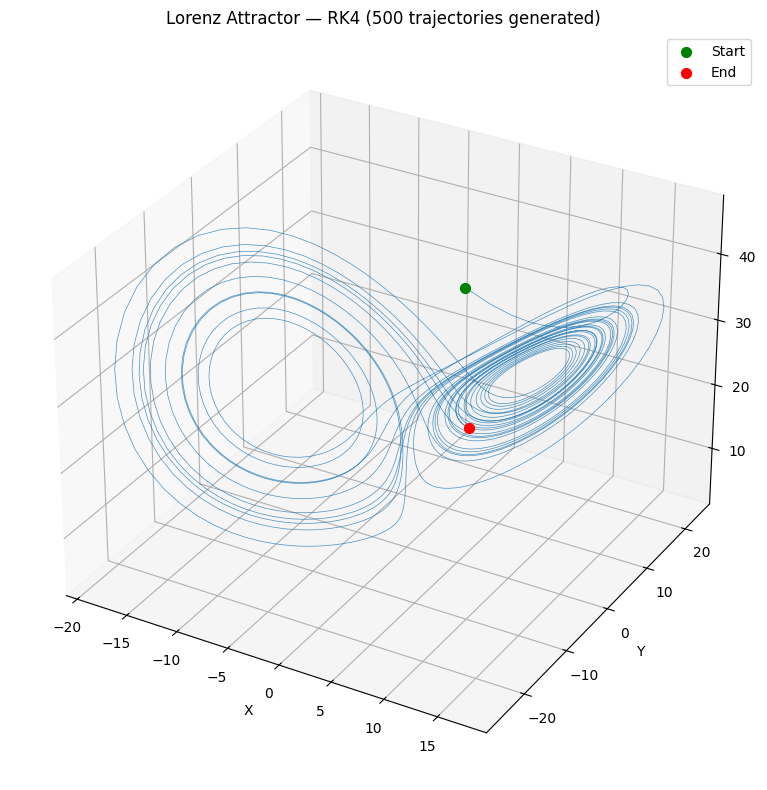

In [2]:
class LorenzRK4:
    def __init__(self, sigma=10.0, rho=28.0, beta=8.0/3.0):
        self.sigma, self.rho, self.beta = sigma, rho, beta

    def derivative(self, state):
        x, y, z = state
        return np.array([
            self.sigma * (y - x),
            x * (self.rho - z) - y,
            x * y - self.beta * z
        ])

    def step(self, state, dt):
        k1 = self.derivative(state)
        k2 = self.derivative(state + 0.5*dt*k1)
        k3 = self.derivative(state + 0.5*dt*k2)
        k4 = self.derivative(state + dt*k3)
        return state + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    def solve(self, initial_state, dt=0.01, T=25.0):
        num_steps = int(T / dt)
        trajectory = np.zeros((num_steps, 3))
        trajectory[0] = initial_state.copy()
        state = initial_state.copy()
        for i in range(1, num_steps):
            state = self.step(state, dt)
            trajectory[i] = state
        return trajectory

print(f'Generating {NUM_TRAJECTORIES} trajectories...')
solver = LorenzRK4()
trajectories = []
np.random.seed(42)
t0 = time.time()

for i in range(NUM_TRAJECTORIES):
    x0 = np.random.uniform(-15, 15)
    y0 = np.random.uniform(-15, 25)
    z0 = np.random.uniform(5, 35)
    traj = solver.solve(np.array([x0, y0, z0]), dt=DT, T=T_SIM)
    trajectories.append(traj)
    if (i+1) % 100 == 0:
        print(f'  {i+1}/{NUM_TRAJECTORIES} done...')

simulation_time = time.time() - t0
trajectories = np.array(trajectories)
print(f'Done in {simulation_time:.2f}s  |  Shape: {trajectories.shape}')

# Plot attractor
fig = plt.figure(figsize=(10,8))
ax  = fig.add_subplot(111, projection='3d')
traj = trajectories[0]
ax.plot(traj[:,0], traj[:,1], traj[:,2], lw=0.5, alpha=0.8)
ax.scatter(*traj[0],  c='green', s=50, label='Start')
ax.scatter(*traj[-1], c='red',   s=50, label='End')
ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
ax.set_title('Lorenz Attractor — RK4 (500 trajectories generated)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/01_lorenz_attractor.png', dpi=120)
plt.show()

## Section 2: Dataset Generation (Lookback = 50)

In [3]:
print(f'Building sliding-window dataset (lookback={LOOKBACK})...')

X_list, y_list = [], []
for traj in trajectories:
    for i in range(len(traj) - LOOKBACK):
        X_list.append(traj[i:i+LOOKBACK])
        y_list.append(traj[i+LOOKBACK])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)
print(f'Total samples : {len(X):,}')
print(f'Input shape   : {X.shape}')
print(f'Output shape  : {y.shape}')

# Normalise using training split stats only
n_train = int(0.70 * len(X))
n_val   = int(0.15 * len(X))

scaler = StandardScaler()
X_flat = X.reshape(-1, 3)
scaler.fit(X_flat[:n_train * LOOKBACK])   # fit on train only!

X_scaled = scaler.transform(X_flat).reshape(X.shape)
y_scaled = scaler.transform(y)

X_train, y_train = X_scaled[:n_train],              y_scaled[:n_train]
X_val,   y_val   = X_scaled[n_train:n_train+n_val], y_scaled[n_train:n_train+n_val]
X_test,  y_test  = X_scaled[n_train+n_val:],        y_scaled[n_train+n_val:]

print(f'Train : {len(X_train):,}  |  Val : {len(X_val):,}  |  Test : {len(X_test):,}')

def make_loader(X, y, shuffle=False):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(device=='cuda'))

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader   = make_loader(X_val,   y_val)
test_loader  = make_loader(X_test,  y_test)
print('DataLoaders ready.')

Building sliding-window dataset (lookback=50)...
Total samples : 1,225,000
Input shape   : (1225000, 50, 3)
Output shape  : (1225000, 3)
Train : 857,500  |  Val : 183,750  |  Test : 183,750
DataLoaders ready.


## Section 3: Model Definitions

Four models:
1. **MLP** — flat baseline (same as original)
2. **Improved LSTM** — hidden=256, layers=3, gradient clipping, scheduler
3. **TCN** — Temporal Convolutional Network with dilated causal convolutions
4. **ESN** — Echo State Network (trains in seconds, no GPU needed)

In [4]:
# ── 1. MLP (baseline, unchanged) ──────────────────────────────
class MLPModel(nn.Module):
    def __init__(self, lookback=LOOKBACK):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(lookback*3, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64),         nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64,  32),         nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32,  3)
        )
    def forward(self, x):
        return self.net(x.flatten(1))


# ── 2. Improved LSTM ──────────────────────────────────────────
class ImprovedLSTM(nn.Module):
    def __init__(self, lookback=LOOKBACK, hidden=256, layers=3, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(3, hidden, layers,
                            batch_first=True,
                            dropout=dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden, 64), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 3)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])   # last timestep only


# ── 3. TCN — Temporal Convolutional Network ───────────────────
class CausalConv1d(nn.Module):
    """Causal (left-padded) dilated convolution"""
    def __init__(self, in_ch, out_ch, kernel=3, dilation=1):
        super().__init__()
        self.pad  = (kernel - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel,
                              padding=self.pad, dilation=dilation)
    def forward(self, x):
        return self.conv(x)[:, :, :-self.pad] if self.pad else self.conv(x)

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=3, dilation=1, dropout=0.2):
        super().__init__()
        self.conv1  = CausalConv1d(in_ch,  out_ch, kernel, dilation)
        self.conv2  = CausalConv1d(out_ch, out_ch, kernel, dilation)
        self.relu   = nn.ReLU()
        self.drop   = nn.Dropout(dropout)
        self.resid  = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        self.norm1  = nn.BatchNorm1d(out_ch)
        self.norm2  = nn.BatchNorm1d(out_ch)
    def forward(self, x):
        out = self.drop(self.relu(self.norm1(self.conv1(x))))
        out = self.drop(self.relu(self.norm2(self.conv2(out))))
        return self.relu(out + self.resid(x))

class TCNModel(nn.Module):
    def __init__(self, lookback=LOOKBACK, channels=64, dropout=0.2):
        super().__init__()
        # 4 blocks with exponentially increasing dilation
        self.tcn = nn.Sequential(
            TCNBlock(3,        channels,   dilation=1,  dropout=dropout),
            TCNBlock(channels, channels,   dilation=2,  dropout=dropout),
            TCNBlock(channels, channels*2, dilation=4,  dropout=dropout),
            TCNBlock(channels*2, channels*2, dilation=8, dropout=dropout),
        )
        self.head = nn.Sequential(
            nn.Linear(channels*2, 32), nn.ReLU(),
            nn.Linear(32, 3)
        )
    def forward(self, x):           # x: (batch, lookback, 3)
        x = x.permute(0, 2, 1)     # -> (batch, 3, lookback)
        out = self.tcn(x)           # -> (batch, channels*2, lookback)
        return self.head(out[:, :, -1])  # last timestep


# ── 4. Echo State Network ─────────────────────────────────────
class EchoStateNetwork:
    """
    Reservoir Computing / Echo State Network.
    Only the output (readout) weights are trained — via ridge regression.
    No backpropagation. Trains in seconds.

    Key insight: the fixed random reservoir IS a dynamical system.
    It naturally echoes the attractor structure of the Lorenz system.
    """
    def __init__(self, n_reservoir=1000, spectral_radius=1.2,
                 sparsity=0.05, leaking_rate=0.3, ridge_alpha=1e-6,
                 washout=200):
        self.N  = n_reservoir
        self.sr = spectral_radius
        self.sp = sparsity
        self.lr = leaking_rate
        self.alpha   = ridge_alpha
        self.washout = washout

    def _build_reservoir(self, n_input):
        np.random.seed(0)
        # Sparse random reservoir weight matrix
        W = np.random.randn(self.N, self.N)
        W[np.random.rand(self.N, self.N) > self.sp] = 0.0
        # Scale to desired spectral radius
        eigvals = np.linalg.eigvals(W)
        W *= self.sr / np.max(np.abs(eigvals))
        self.W    = W
        self.W_in = np.random.randn(self.N, n_input) * 0.1

    def _run_reservoir(self, data):
        """Drive reservoir with input data, collect states."""
        T, n_in = data.shape
        states = np.zeros((T, self.N))
        x = np.zeros(self.N)
        for t in range(T):
            x = ((1 - self.lr) * x
                 + self.lr * np.tanh(self.W @ x + self.W_in @ data[t]))
            states[t] = x
        return states

    def fit(self, train_data):
        """
        train_data: (T, 3) array of normalised Lorenz states.
        Learns a one-step-ahead predictor.
        """
        self._build_reservoir(train_data.shape[1])
        print(f'  ESN: running reservoir on {len(train_data):,} steps...')
        states = self._run_reservoir(train_data)
        # Discard washout; predict t+1 from state at t
        X_r = states[self.washout:-1]
        y_r = train_data[self.washout+1:]
        print(f'  ESN: fitting ridge regression ({X_r.shape[0]:,} samples)...')
        self.readout = Ridge(alpha=self.alpha)
        self.readout.fit(X_r, y_r)
        self._last_state = states[-1]
        print(f'  ESN: training complete.')

    def predict_one_step(self, data):
        """Single-step predictions on (T,3) input — for test-set RMSE."""
        states = self._run_reservoir(data)
        return self.readout.predict(states)

    def rollout(self, seed_data, n_steps):
        """
        Autoregressive rollout.
        seed_data: (warmup, 3) — drives reservoir into correct state.
        """
        # Warm up reservoir with seed
        x = np.zeros(self.N)
        for u in seed_data:
            x = ((1-self.lr)*x
                 + self.lr*np.tanh(self.W @ x + self.W_in @ u))
        # Autoregressive loop
        preds = []
        u = seed_data[-1]
        for _ in range(n_steps):
            x = ((1-self.lr)*x
                 + self.lr*np.tanh(self.W @ x + self.W_in @ u))
            u = self.readout.predict([x])[0]
            preds.append(u)
        return np.array(preds)


# Instantiate deep models
mlp_model  = MLPModel().to(device)
lstm_model = ImprovedLSTM().to(device)
tcn_model  = TCNModel().to(device)

print('Model parameters:')
for name, m in [('MLP', mlp_model), ('LSTM (improved)', lstm_model), ('TCN', tcn_model)]:
    p = sum(p.numel() for p in m.parameters())
    print(f'  {name:20s}: {p:,}')

Model parameters:
  MLP                 : 29,763
  LSTM (improved)     : 1,336,579
  TCN                 : 224,579


## Section 4: Training — Deep Models (MLP, LSTM, TCN)

TRAINING MLP


Training MLP:   0%|          | 0/50 [00:00<?, ?epoch/s]

[MLP] Done — best val=0.00223  time=1986.0s
✓ MLP saved.

TRAINING IMPROVED LSTM


Training LSTM:   0%|          | 0/12 [00:00<?, ?epoch/s]

[LSTM] Done — best val=0.00065  time=2444.2s
✓ LSTM saved.

TRAINING TCN


Training TCN:   0%|          | 0/80 [00:00<?, ?epoch/s]

[TCN] Done — best val=0.00000  time=9542.5s
✓ TCN saved.


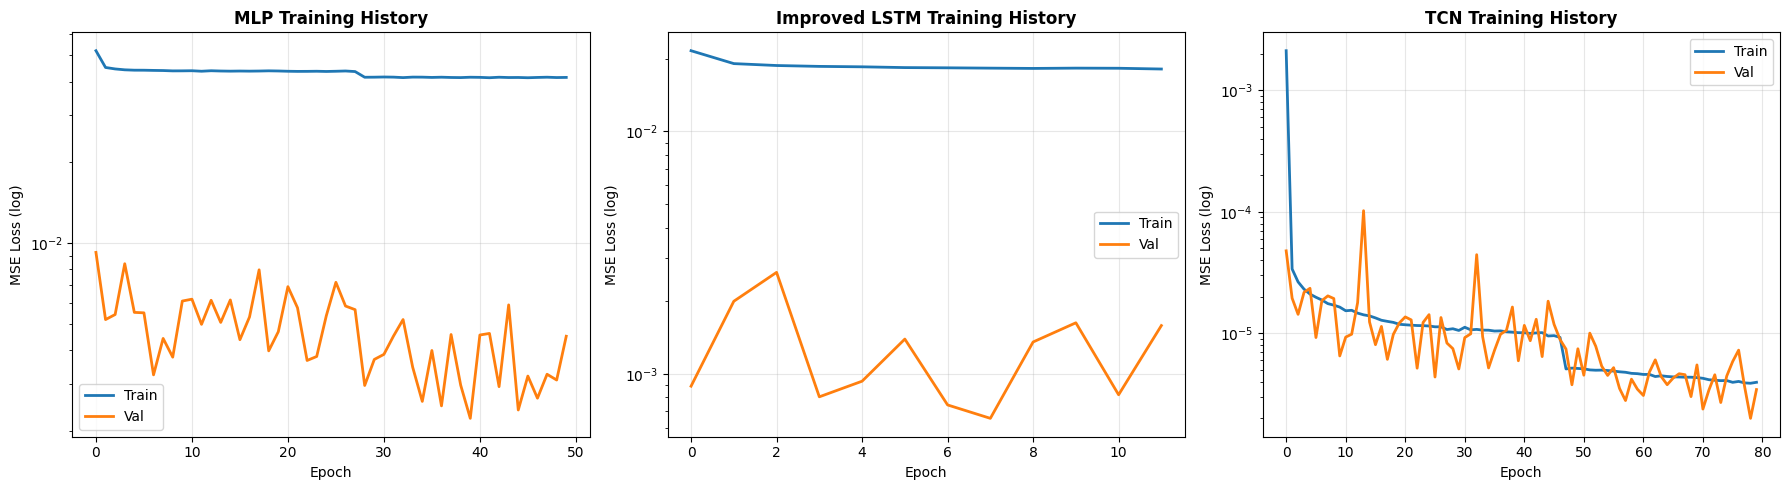

In [5]:
from tqdm.notebook import tqdm

def train_deep_model(model, train_loader, val_loader,
                     epochs=EPOCHS, lr=LR, clip=1.0, name='Model'):
    optimizer  = Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler  = ReduceLROnPlateau(optimizer, mode='min',
                                   patience=20, factor=0.5,
                                   min_lr=1e-6)
    criterion  = nn.MSELoss()
    train_hist, val_hist = [], []
    best_val   = float('inf')
    best_state = None
    t0 = time.time()
    pbar = tqdm(range(1, epochs+1), desc=f'Training {name}', unit='epoch')
    for epoch in pbar:
        # ── Train ──
        model.train()
        train_loss = 0.0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(Xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)
        # ── Validate ──
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                val_loss += criterion(model(Xb), yb).item()
        val_loss /= len(val_loader)
        scheduler.step(val_loss)
        train_hist.append(train_loss)
        val_hist.append(val_loss)
        # Save best weights
        if val_loss < best_val:
            best_val   = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        # Update progress bar
        pbar.set_postfix({
            'train': f'{train_loss:.5f}',
            'val':   f'{val_loss:.5f}',
            'best':  f'{best_val:.5f}',
            'lr':    f'{optimizer.param_groups[0]["lr"]:.1e}'
        })
    # Restore best weights
    model.load_state_dict(best_state)
    total_time = time.time() - t0
    print(f'[{name}] Done — best val={best_val:.5f}  time={total_time:.1f}s')
    return train_hist, val_hist, total_time


# ── Uncomment to RELOAD instead of retraining ──────────────
# mlp_model.load_state_dict(torch.load(f'{OUTPUT_DIR}/mlp_model.pth'))
# lstm_model.load_state_dict(torch.load(f'{OUTPUT_DIR}/lstm_model.pth'))
# tcn_model.load_state_dict(torch.load(f'{OUTPUT_DIR}/tcn_model.pth'))
# print('Models reloaded.')

print('='*60)
print('TRAINING MLP')
print('='*60)
mlp_th, mlp_vh, mlp_time = train_deep_model(
    mlp_model, train_loader, val_loader, epochs=50, name='MLP')
torch.save(mlp_model.state_dict(), f'{OUTPUT_DIR}/mlp_model.pth')
print('✓ MLP saved.')

print('\n' + '='*60)
print('TRAINING IMPROVED LSTM')
print('='*60)
lstm_th, lstm_vh, lstm_time = train_deep_model(
    lstm_model, train_loader, val_loader, epochs=12, name='LSTM')
torch.save(lstm_model.state_dict(), f'{OUTPUT_DIR}/lstm_model.pth')
print('✓ LSTM saved.')

print('\n' + '='*60)
print('TRAINING TCN')
print('='*60)
tcn_th, tcn_vh, tcn_time = train_deep_model(
    tcn_model, train_loader, val_loader, epochs=80, name='TCN')
torch.save(tcn_model.state_dict(), f'{OUTPUT_DIR}/tcn_model.pth')
print('✓ TCN saved.')

# Plot training histories
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, th, vh, name in zip(
        axes,
        [mlp_th, lstm_th, tcn_th],
        [mlp_vh, lstm_vh, tcn_vh],
        ['MLP', 'Improved LSTM', 'TCN']):
    ax.semilogy(th, label='Train', lw=2)
    ax.semilogy(vh, label='Val',   lw=2)
    ax.set_title(f'{name} Training History', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE Loss (log)')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/02_training_history.png', dpi=120)
plt.show()

## Section 5: Training — Echo State Network (ESN)

ESN does **not** use mini-batch gradient descent. It:
1. Drives a fixed random reservoir with the training sequence
2. Fits a Ridge regression on the collected reservoir states

Training takes **seconds**, not minutes.

In [6]:
print('='*60)
print('TRAINING ECHO STATE NETWORK (ESN)')
print('='*60)

# Use only 30% of trajectories — ESN doesn't need all data
n_train_trajs = int(NUM_TRAJECTORIES * 0.30)
esn_seq = []
for traj in trajectories[:n_train_trajs]:
    esn_seq.append(traj)
esn_sequence = np.vstack(esn_seq).astype(np.float64)

# Normalise with same scaler
esn_sequence_scaled = scaler.transform(esn_sequence)
print(f'ESN training sequence length: {len(esn_sequence_scaled):,} steps')

t0 = time.time()
esn = EchoStateNetwork(
    n_reservoir     = 500,
    spectral_radius = 0.95,
    sparsity        = 0.02,
    leaking_rate    = 0.5,
    ridge_alpha     = 1e-4,
    washout         = 200
)
esn.fit(esn_sequence_scaled)
esn_time = time.time() - t0
print(f'ESN training time: {esn_time:.2f}s')

# Save ESN
import pickle
with open(f'{OUTPUT_DIR}/esn_model.pkl', 'wb') as f:
    pickle.dump(esn, f)
print('✓ ESN saved.')

# Single-step predictions on test set
print('Computing ESN single-step test predictions...')
esn_preds_scaled = []
for i in range(len(X_test)):
    window = X_test[i].astype(np.float64)
    states = esn._run_reservoir(window)
    pred   = esn.readout.predict(states[[-1]])
    esn_preds_scaled.append(pred[0])

esn_preds_scaled = np.array(esn_preds_scaled)
print(f'ESN predictions shape: {esn_preds_scaled.shape}')

TRAINING ECHO STATE NETWORK (ESN)
ESN training sequence length: 375,000 steps
  ESN: running reservoir on 375,000 steps...
  ESN: fitting ridge regression (374,799 samples)...
  ESN: training complete.
ESN training time: 32.69s
✓ ESN saved.
Computing ESN single-step test predictions...
ESN predictions shape: (183750, 3)


## Section 6: Evaluation — Single-Step Accuracy


SINGLE-STEP TEST ACCURACY
---------------------------------------------
Model                       RMSE         MAE
---------------------------------------------
MLP                     0.402675    0.318396
LSTM (improved)         0.217935    0.164254
TCN                     0.012793    0.007889
ESN                     0.013355    0.009616


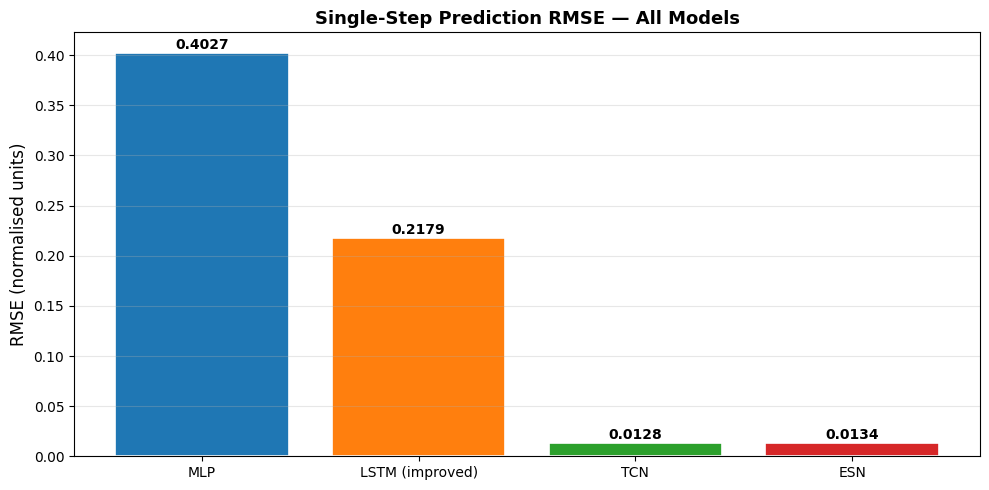

In [7]:
def get_deep_preds(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for Xb, _ in loader:
            preds.append(model(Xb.to(device)).cpu().numpy())
    return np.vstack(preds)

# Scaled predictions
mlp_pred_s  = get_deep_preds(mlp_model,  test_loader)
lstm_pred_s = get_deep_preds(lstm_model, test_loader)
tcn_pred_s  = get_deep_preds(tcn_model,  test_loader)

# Denormalise everything
y_test_dn   = scaler.inverse_transform(y_test)
mlp_dn      = scaler.inverse_transform(mlp_pred_s)
lstm_dn     = scaler.inverse_transform(lstm_pred_s)
tcn_dn      = scaler.inverse_transform(tcn_pred_s)
esn_dn      = scaler.inverse_transform(esn_preds_scaled)

def rmse_mae(pred, true):
    err  = pred - true
    rmse = float(np.sqrt(np.mean(err**2)))
    mae  = float(np.mean(np.abs(err)))
    return rmse, mae

results = {}
for name, pred in [('MLP', mlp_dn), ('LSTM (improved)', lstm_dn),
                   ('TCN', tcn_dn),  ('ESN', esn_dn)]:
    r, m = rmse_mae(pred, y_test_dn)
    results[name] = {'RMSE': r, 'MAE': m}

print('\nSINGLE-STEP TEST ACCURACY')
print('-'*45)
print(f'{"Model":20s}  {"RMSE":>10s}  {"MAE":>10s}')
print('-'*45)
for name, vals in results.items():
    print(f'{name:20s}  {vals["RMSE"]:10.6f}  {vals["MAE"]:10.6f}')

# Bar chart
fig, ax = plt.subplots(figsize=(10, 5))
names  = list(results.keys())
rmses  = [results[n]['RMSE'] for n in names]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = ax.bar(names, rmses, color=colors, edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, rmses):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
            f'{v:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('RMSE (normalised units)', fontsize=12)
ax.set_title('Single-Step Prediction RMSE — All Models', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/03_rmse_comparison.png', dpi=120)
plt.show()

## Section 7: Multi-Step Rollout Evaluation

Generating 200-step rollouts...
Rollouts done. Computing L2 errors...

200-STEP ROLLOUT L2 ERROR
---------------------------------------------
Model                    Mean L2      Max L2
---------------------------------------------
MLP                       9.5357     28.1619
LSTM (improved)           8.5379     22.1789
TCN                       2.6097     13.7378
ESN                       5.8002     26.0734


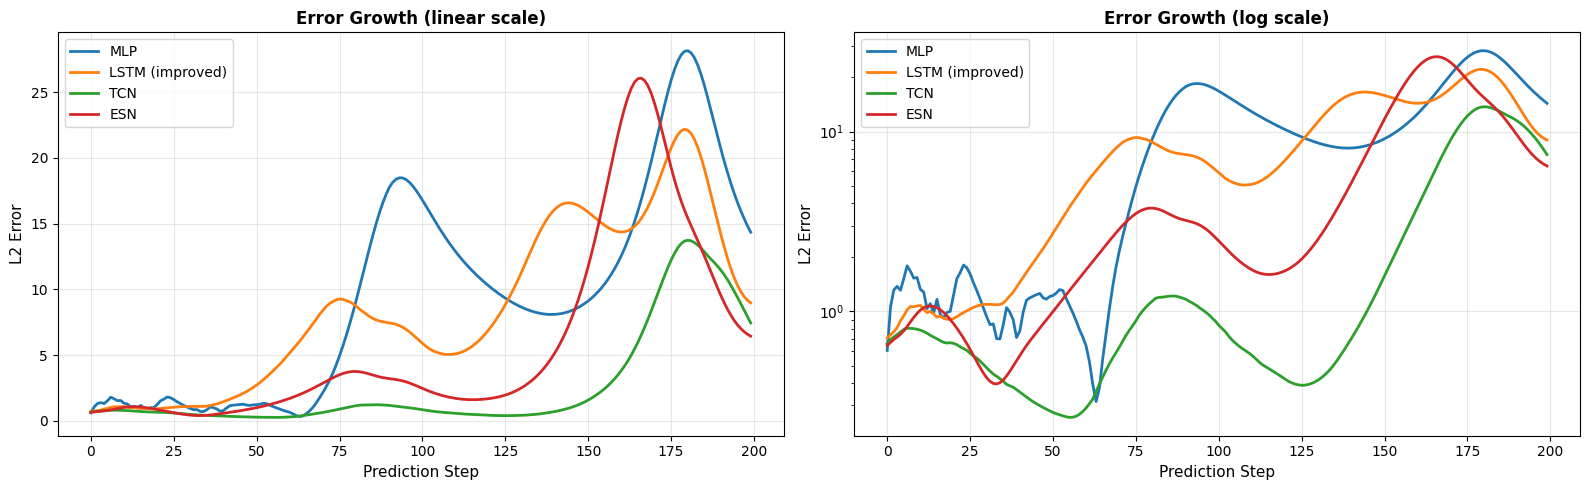

In [8]:
print(f'Generating {ROLLOUT_STEPS}-step rollouts...')

# Reference rollout from true solver
ref_start = scaler.inverse_transform(X_test[0])[-1]  # last state of first test window
ref_rollout = [ref_start]
for _ in range(ROLLOUT_STEPS - 1):
    ref_rollout.append(solver.step(ref_rollout[-1], DT))
ref_rollout = np.array(ref_rollout)

# Deep model autoregressive rollout
def deep_rollout(model, init_window_scaled, n_steps):
    model.eval()
    preds = []
    win   = init_window_scaled.copy()  # (LOOKBACK, 3)
    with torch.no_grad():
        for _ in range(n_steps):
            x  = torch.tensor(win[np.newaxis], dtype=torch.float32).to(device)
            p  = model(x).cpu().numpy()[0]
            preds.append(p)
            win = np.vstack([win[1:], p])
    return scaler.inverse_transform(np.array(preds))

mlp_ro  = deep_rollout(mlp_model,  X_test[0], ROLLOUT_STEPS)
lstm_ro = deep_rollout(lstm_model, X_test[0], ROLLOUT_STEPS)
tcn_ro  = deep_rollout(tcn_model,  X_test[0], ROLLOUT_STEPS)

# ESN rollout — warm up with the test seed window
esn_ro = esn.rollout(X_test[0].astype(np.float64), n_steps=ROLLOUT_STEPS)
esn_ro = scaler.inverse_transform(esn_ro)

print('Rollouts done. Computing L2 errors...')

def l2_error(pred, ref):
    return np.sqrt(np.mean((pred - ref)**2, axis=1))

mlp_err  = l2_error(mlp_ro,  ref_rollout)
lstm_err = l2_error(lstm_ro, ref_rollout)
tcn_err  = l2_error(tcn_ro,  ref_rollout)
esn_err  = l2_error(esn_ro,  ref_rollout)

rollout_results = {
    'MLP':            {'mean': mlp_err.mean(),  'max': mlp_err.max()},
    'LSTM (improved)':{'mean': lstm_err.mean(), 'max': lstm_err.max()},
    'TCN':            {'mean': tcn_err.mean(),  'max': tcn_err.max()},
    'ESN':            {'mean': esn_err.mean(),  'max': esn_err.max()},
}

print(f'\n{ROLLOUT_STEPS}-STEP ROLLOUT L2 ERROR')
print('-'*45)
print(f'{"Model":20s}  {"Mean L2":>10s}  {"Max L2":>10s}')
print('-'*45)
for name, vals in rollout_results.items():
    print(f'{name:20s}  {vals["mean"]:10.4f}  {vals["max"]:10.4f}')

# Error horizon plot
steps = np.arange(ROLLOUT_STEPS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728']
labels = ['MLP','LSTM (improved)','TCN','ESN']
errors = [mlp_err, lstm_err, tcn_err, esn_err]

for ax, scale in [(ax1, 'linear'), (ax2, 'log')]:
    for err, lbl, col in zip(errors, labels, colors):
        ax.plot(steps, err, label=lbl, lw=2, color=col)
    ax.set_xlabel('Prediction Step', fontsize=11)
    ax.set_ylabel('L2 Error', fontsize=11)
    ax.set_yscale(scale)
    ax.set_title(f'Error Growth ({scale} scale)', fontweight='bold')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/04_error_horizon.png', dpi=120)
plt.show()

## Section 8: Rollout Trajectory Comparison

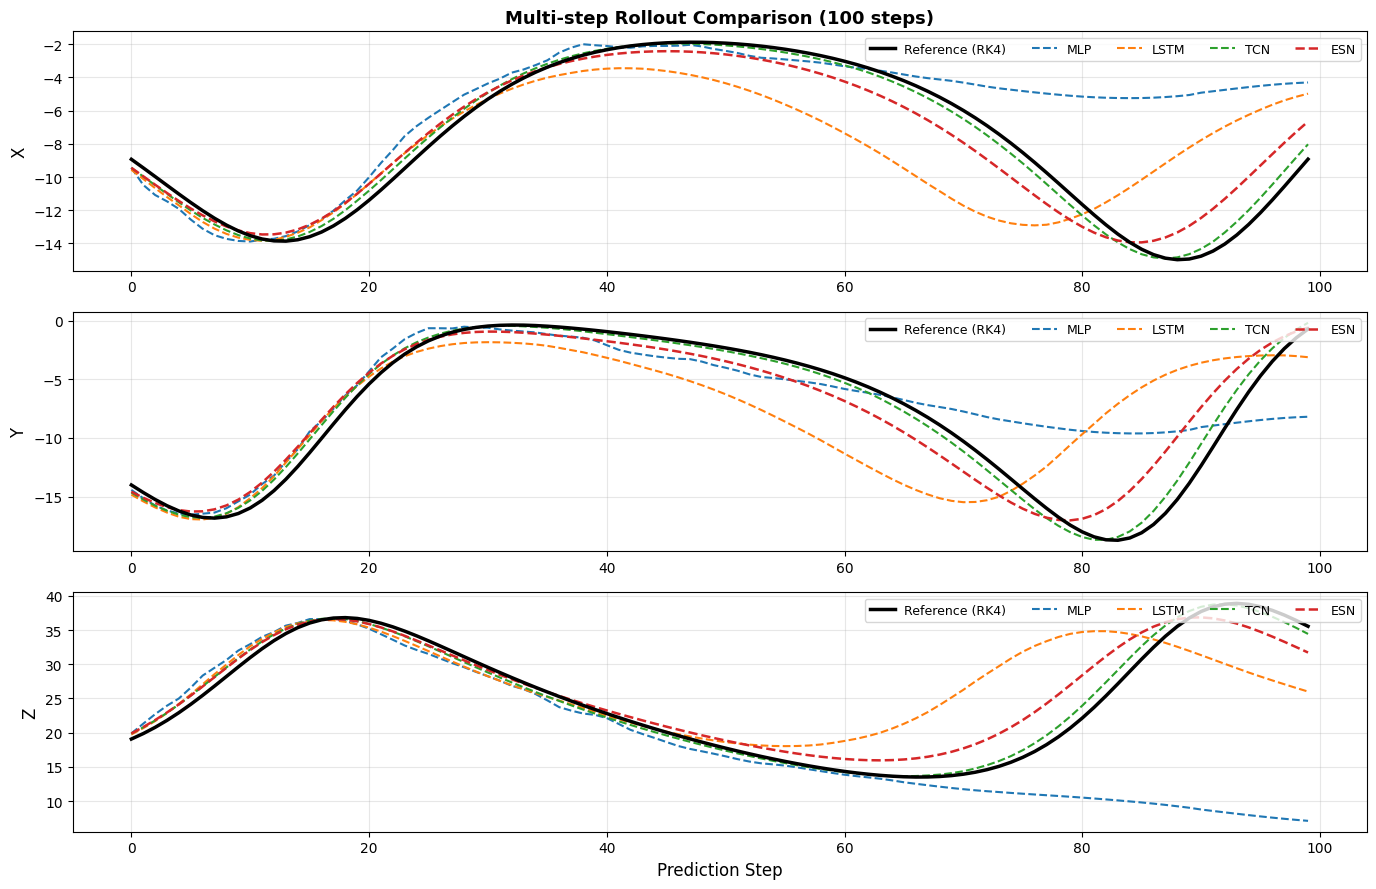

In [9]:
horizon = 100   # show first 100 steps
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for i, (ax, lbl) in enumerate(zip(axes, ['X', 'Y', 'Z'])):
    ax.plot(steps[:horizon], ref_rollout[:horizon,i],
            'k-',  lw=2.5, label='Reference (RK4)', zorder=5)
    ax.plot(steps[:horizon], mlp_ro[:horizon,i],
            '--',  lw=1.5, label='MLP',  color='#1f77b4')
    ax.plot(steps[:horizon], lstm_ro[:horizon,i],
            '--',  lw=1.5, label='LSTM', color='#ff7f0e')
    ax.plot(steps[:horizon], tcn_ro[:horizon,i],
            '--',  lw=1.5, label='TCN',  color='#2ca02c')
    ax.plot(steps[:horizon], esn_ro[:horizon,i],
            '--',  lw=1.8, label='ESN',  color='#d62728')
    ax.set_ylabel(lbl, fontsize=12)
    ax.legend(loc='upper right', ncol=5, fontsize=9)
    ax.grid(True, alpha=0.3)
    if i == 0:
        ax.set_title('Multi-step Rollout Comparison (100 steps)',
                     fontsize=13, fontweight='bold')

axes[-1].set_xlabel('Prediction Step', fontsize=12)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/05_rollout_comparison.png', dpi=120)
plt.show()

## Section 9: Phase Space — ESN vs Reference

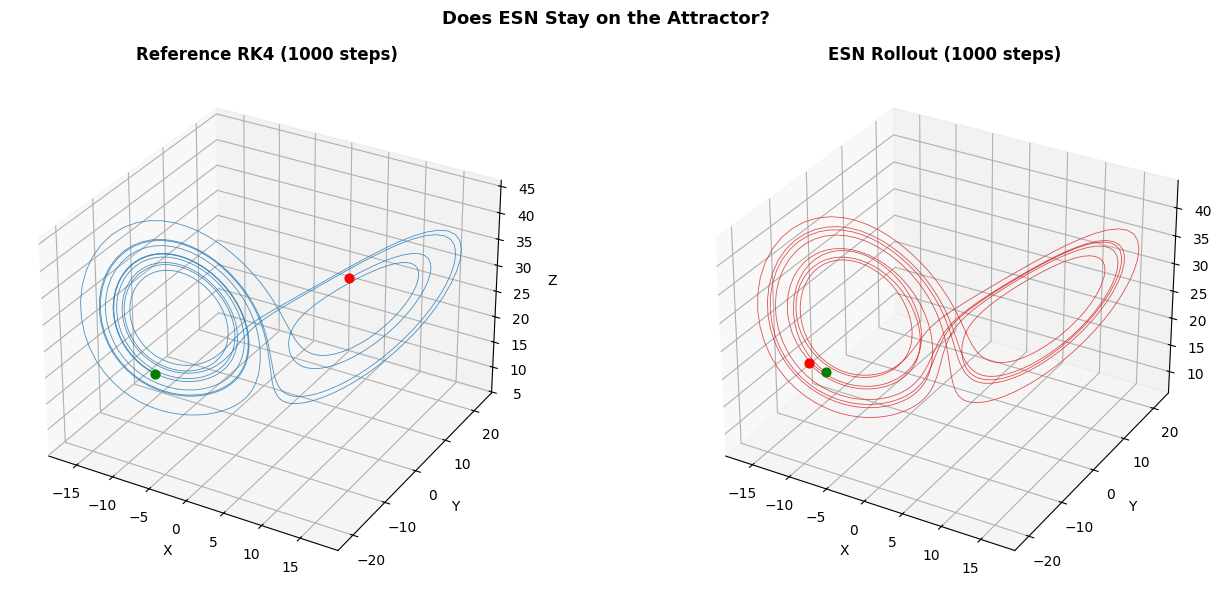

In [10]:
# Long ESN rollout to check if it stays on the attractor
long_steps = 1000
esn_long = esn.rollout(X_test[0].astype(np.float64), n_steps=long_steps)
esn_long = scaler.inverse_transform(esn_long)

ref_long = [ref_start]
for _ in range(long_steps - 1):
    ref_long.append(solver.step(ref_long[-1], DT))
ref_long = np.array(ref_long)

fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                          subplot_kw={'projection': '3d'})

for ax, data, title, col in zip(
        axes,
        [ref_long, esn_long],
        ['Reference RK4 (1000 steps)', 'ESN Rollout (1000 steps)'],
        ['#1f77b4', '#d62728']):
    ax.plot(data[:,0], data[:,1], data[:,2], lw=0.6, alpha=0.8, color=col)
    ax.scatter(*data[0],  c='green', s=40)
    ax.scatter(*data[-1], c='red',   s=40)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')

plt.suptitle('Does ESN Stay on the Attractor?', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/06_phase_space_esn.png', dpi=120)
plt.show()

## Section 10: Final Summary

In [11]:
print('\n' + '='*65)
print('COMPLETE RESULTS SUMMARY')
print('='*65)

print(f'\nDataset:')
print(f'  Trajectories : {NUM_TRAJECTORIES}')
print(f'  Lookback     : {LOOKBACK} steps')
print(f'  Train/Val/Test samples : {len(X_train):,} / {len(X_val):,} / {len(X_test):,}')

print(f'\nSINGLE-STEP RMSE (test set, normalised units):')
print(f'  {"Model":20s}  {"RMSE":>10s}  {"MAE":>10s}')
print(f'  {"-"*45}')
for name, vals in results.items():
    print(f'  {name:20s}  {vals["RMSE"]:10.6f}  {vals["MAE"]:10.6f}')

print(f'\n{ROLLOUT_STEPS}-STEP ROLLOUT L2 ERROR (original units):')
print(f'  {"Model":20s}  {"Mean L2":>10s}  {"Max L2":>10s}')
print(f'  {"-"*45}')
for name, vals in rollout_results.items():
    print(f'  {name:20s}  {vals["mean"]:10.4f}  {vals["max"]:10.4f}')

print(f'\nTRAINING TIMES:')
print(f'  MLP  : {mlp_time:.1f}s')
print(f'  LSTM : {lstm_time:.1f}s')
print(f'  TCN  : {tcn_time:.1f}s')
print(f'  ESN  : {esn_time:.2f}s  ← trains in seconds!')

# Save results to CSV
rows = []
for name in results:
    rows.append({
        'Model'          : name,
        'RMSE'           : results[name]['RMSE'],
        'MAE'            : results[name]['MAE'],
        'Rollout_Mean_L2': rollout_results[name]['mean'],
        'Rollout_Max_L2' : rollout_results[name]['max'],
    })

df = pd.DataFrame(rows)
df.to_csv(f'{OUTPUT_DIR}/results_summary.csv', index=False)
print(f'\nResults saved to {OUTPUT_DIR}/results_summary.csv')

print('\n' + '='*65)
print('ALL DONE — download outputs from /kaggle/working/')
print('='*65)


COMPLETE RESULTS SUMMARY

Dataset:
  Trajectories : 500
  Lookback     : 50 steps
  Train/Val/Test samples : 857,500 / 183,750 / 183,750

SINGLE-STEP RMSE (test set, normalised units):
  Model                       RMSE         MAE
  ---------------------------------------------
  MLP                     0.402675    0.318396
  LSTM (improved)         0.217935    0.164254
  TCN                     0.012793    0.007889
  ESN                     0.013355    0.009616

200-STEP ROLLOUT L2 ERROR (original units):
  Model                    Mean L2      Max L2
  ---------------------------------------------
  MLP                       9.5357     28.1619
  LSTM (improved)           8.5379     22.1789
  TCN                       2.6097     13.7378
  ESN                       5.8002     26.0734

TRAINING TIMES:
  MLP  : 1986.0s
  LSTM : 2444.2s
  TCN  : 9542.5s
  ESN  : 32.69s  ← trains in seconds!

Results saved to /kaggle/working/results_summary.csv

ALL DONE — download outputs from /kaggle/w